<a href="https://colab.research.google.com/github/HyeonnWoo/26-2-DIP-202001601/blob/main/notebook_2026/HW08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nibabel

In [2]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [3]:
h = nib.load('s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


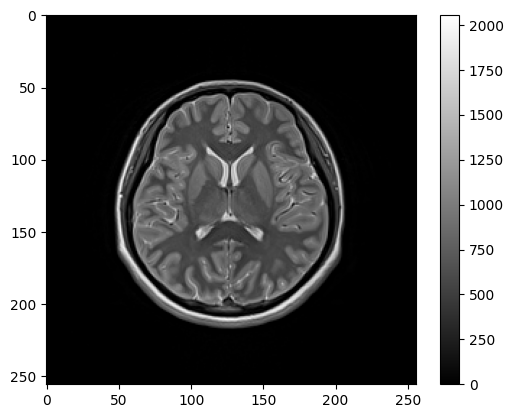

In [4]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

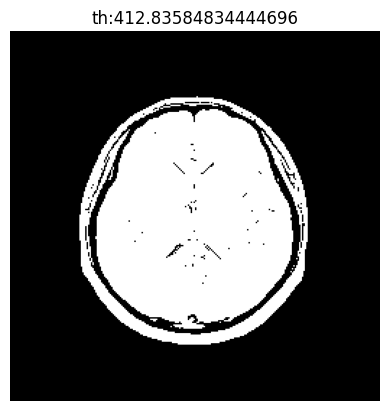

In [14]:
T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
while dT>esp:
  g1 = f[f>T[-1]]
  g2 = f[f<=T[-1]]
  m1 = np.mean(g1)
  m2 = np.mean(g2)
  T.append((m1+m2)/2)

  dT = np.abs(T[-1]-T[-2])
##

bmsk = f>T[-1]
plt.imshow(bmsk,cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

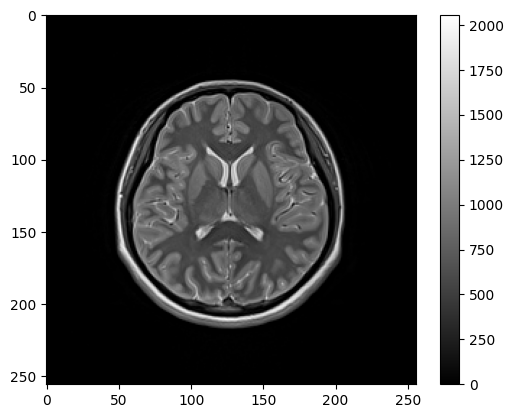

In [7]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

Centroids: [ 64. 128.]
Centroids: [  5.91248043 768.93253625]
Centroids: [ 13.3779618  806.97810069]
Centroids: [ 14.87874927 810.79294742]


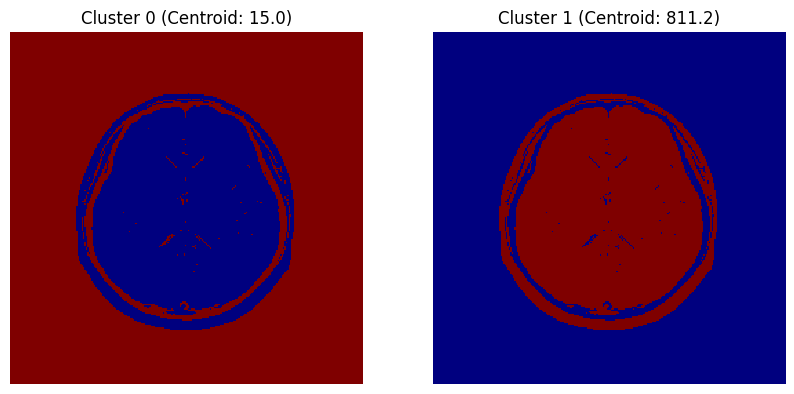

In [8]:
m_vals = np.array([64., 128.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1

while E > eps:
  for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c, axis=-1)

  for i in range(len(m_vals)):
    mask = (cmap == i)
    if np.any(mask):
      m_vals_new[i] = np.mean(f[mask])
    else:
      m_vals_new[i] = m_vals[i]

  E = np.linalg.norm(m_vals - m_vals_new)
  m_vals = m_vals_new.copy()

# 결과 시각화
plt.figure(figsize=(10, 5))
for i in range(len(m_vals)):
  plt.subplot(1, len(m_vals), i + 1)
  plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
  plt.title(f'Cluster {i} (Centroid: {m_vals[i]:.1f})')
  plt.axis('off')
plt.show()

### k = 3 에서의 결과

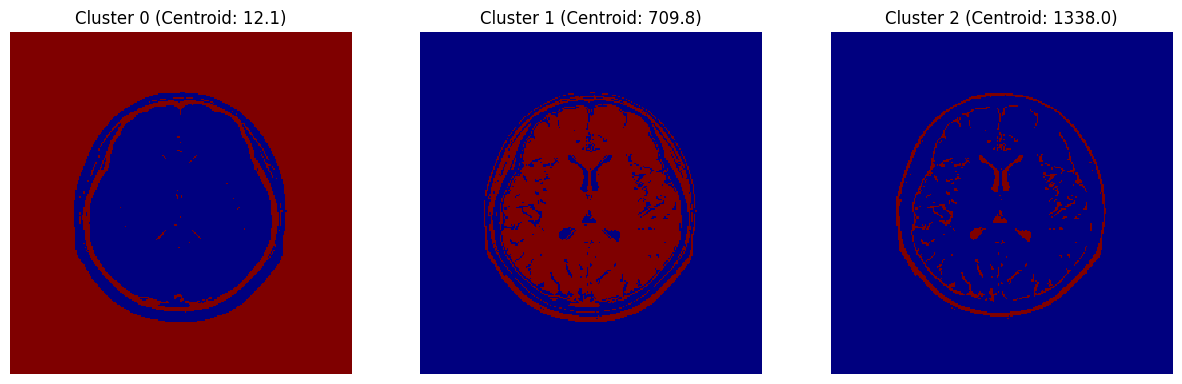

In [9]:
m_vals = np.array([30., 150., 500.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1

while E > eps:
  # 1. 각 픽셀과 군집 중심점 사이의 거리 계산
  for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])

  # 2. 가장 가까운 중심점의 인덱스로 군집 할당
  cmap = np.argmin(c, axis=-1)

  # 3. 중심점 업데이트
  for i in range(len(m_vals)):
    mask = (cmap == i)
    if np.any(mask):
      m_vals_new[i] = np.mean(f[mask])
    else:
      m_vals_new[i] = m_vals[i]

  # 4. 오차 계산
  E = np.linalg.norm(m_vals - m_vals_new)
  m_vals = m_vals_new.copy()

# 결과 시각화
plt.figure(figsize=(15, 5))
for i in range(len(m_vals)):
  plt.subplot(1, len(m_vals), i + 1)
  plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
  plt.title(f'Cluster {i} (Centroid: {m_vals[i]:.1f})')
  plt.axis('off')
plt.show()

### k = 4 에서의 결과

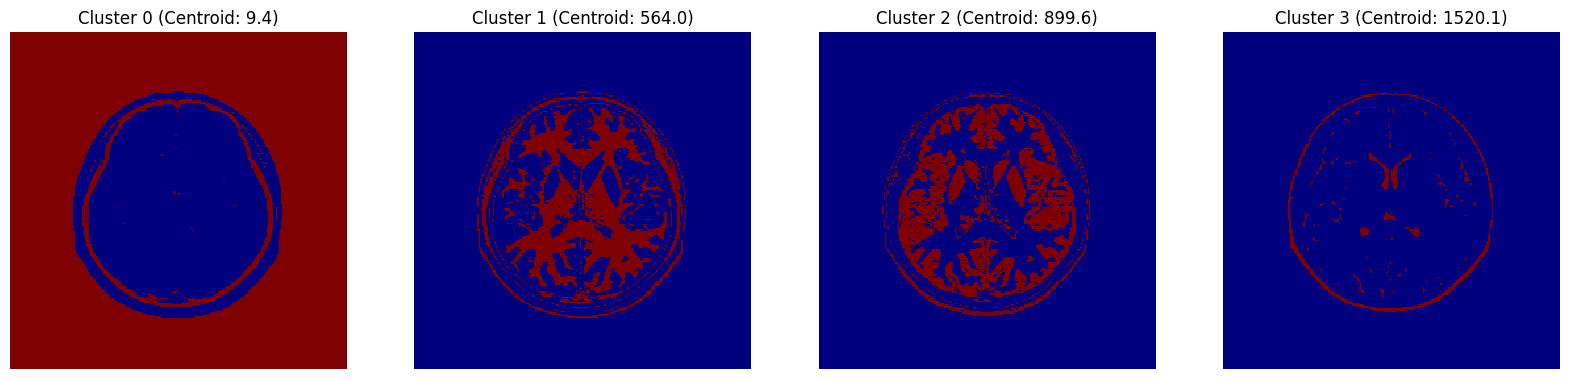

In [10]:
m_vals = np.array([30., 150., 500., 1000.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1

while E > eps:
  # 1. 각 픽셀과 군집 중심점 사이의 거리 계산
  for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])

  # 2. 가장 가까운 중심점의 인덱스로 군집 할당
  cmap = np.argmin(c, axis=-1)

  # 3. 중심점 업데이트
  for i in range(len(m_vals)):
    mask = (cmap == i)
    if np.any(mask):
      m_vals_new[i] = np.mean(f[mask])
    else:
      m_vals_new[i] = m_vals[i]

  # 4. 오차 계산
  E = np.linalg.norm(m_vals - m_vals_new)
  m_vals = m_vals_new.copy()

# 결과 시각화
plt.figure(figsize=(20, 5))
for i in range(len(m_vals)):
  plt.subplot(1, len(m_vals), i + 1)
  plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
  plt.title(f'Cluster {i} (Centroid: {m_vals[i]:.1f})')
  plt.axis('off')
plt.show()